# 03 — Fluxo ponta a ponta: detector → recorte → classificador

**Pergunta:** quanto o fluxo completo melhora em relação ao **fluxo antigo**? O fluxo antigo é YOLO Modelo A com conf 0,5, recorte de 15% e a fusão GhostNetV2 + MobileNetV2.

**Como medimos:**
- **Por objeto:** uma detecção é acerto de MILCO quando cobre um MILCO verdadeiro (IoU ≥ 0,5) e o classificador diz MILCO. Daí saem precisão, recall, F1 e AP50 da classe MILCO.
- **Por imagem:** a AUC de "a imagem tem mina?", usando score = conf × p(MILCO).
- **Ajuste:** em todos os fluxos, exceto o P0, a conf do detector e o limiar de aceite de MILCO foram escolhidos na **validação**.

### Protocolo comum
- **Dados:** SIMD (Marinha Portuguesa, 1170 imagens side-scan, 2010–2021). **MILCO** = objeto com aparência de mina; **NOMBO** = objeto que não é mina.
- **Split:** idêntico ao notebook `sonar_deteccao_comparacao_modelos_V3_AA.ipynb` (arquivos ordenados por nome, `random.Random(42).shuffle`, 70/15/15) → 819 / 175 / 176 imagens. No teste há **109 objetos** (75 MILCO, 34 NOMBO).
- **Seleção sempre na validação** (checkpoint, conf do detector, limiar de aceite, finalista). O teste é usado uma vez, para reportar.
- **Hardware:** máquina local com 2 núcleos de CPU e 4 GB de RAM, **sem GPU**; treinos fatiados e retomáveis (`crop_harness.py` + `fila_recortes.json`).
- **Pesos antigos** (YOLO Modelo A e fusão GhostNetV2 + MobileNetV2) foram apenas lidos, nunca alterados.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.precision", 3); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 90)
sys.path.insert(0, str(Path.cwd()))
import analise_recortes as A

In [2]:
d, escolhido = A.tabela_pipelines()
print("Classificador escolhido na validação:", escolhido)
d.drop(columns=["descrição"])

Classificador escolhido na validação: C_b1_convnextpico_224


,fluxo,conf,aceite MILCO,val F1 MILCO,teste precisão,teste recall,teste F1,teste AP50,TP,FP,FN,imagem AUC
0,P0_antigo,0.50,0.0,0.538,0.837,0.480,0.610,0.502,36,7,39,0.901
1,P1_antigo_ajustado,0.40,0.0,0.585,0.760,0.507,0.608,0.518,38,12,37,0.925
2,P2_detnovo_clsantigo,0.30,0.0,0.596,0.682,0.600,0.638,0.616,45,21,30,0.957
3,C_b1_convnextpico_128,0.30,0.0,0.673,0.722,0.693,0.707,0.651,52,20,23,0.961
4,C_b1_convnextpico_224,0.20,0.6,0.713,0.659,0.720,0.688,0.679,54,28,21,0.961
5,C_b3_margem030,0.10,0.6,0.659,0.557,0.520,0.538,0.689,39,31,36,0.981
6,C_b2_label_smoothing,0.10,0.7,0.688,0.578,0.640,0.608,0.719,48,35,27,0.984
7,C_b5_fundo_3classes,0.10,0.8,0.712,0.596,0.707,0.646,0.714,53,36,22,0.983
8,P3_detantigo_clsnovo,0.20,0.6,0.695,0.704,0.667,0.685,0.631,50,21,25,0.962
9,P4_novo,0.20,0.6,0.713,0.659,0.720,0.688,0.679,54,28,21,0.961


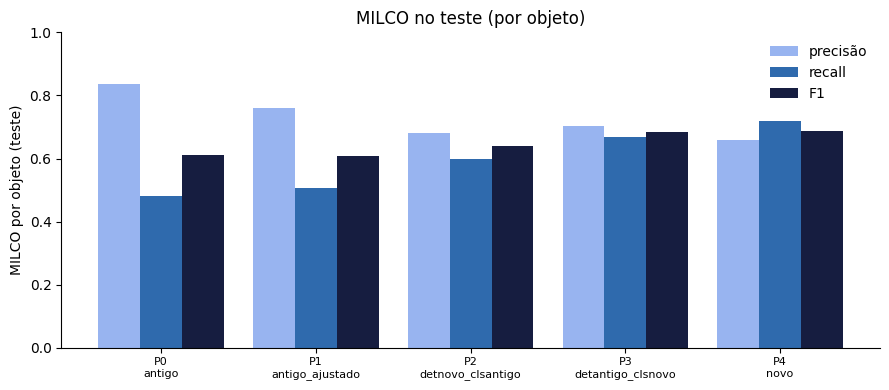

In [3]:
A.grafico_pipelines(); plt.title("MILCO no teste (por objeto)"); plt.tight_layout(); plt.show()

**Leitura** (teste, 75 MILCO):
- **Fluxo antigo (P0):** encontra só **36 de 75 minas** (recall 0,48, F1 0,61). O gargalo é o detector com conf 0,5, que perde 34 minas antes mesmo de classificar.
- **Detector com TTA (P2):** sozinho, já sobe o recall para 0,60.
- **ConvNeXt de recortes no detector antigo (P3):** também melhora (F1 0,685).
- **Fluxo novo (P4: TTA + ConvNeXt-Pico 224, 3 sementes):** **54 de 75 minas** (recall 0,72), **F1 0,69** e AUC por imagem de 0,96 (era 0,90).
- **Uma semente só (P4b):** quase igual (F1 0,68) e 3× mais barata.
- **Blocos + 3 classes (P5):** gera falsos positivos demais (F1 0,58).

**O erro que sobra agora é do detector:** das 21 minas não encontradas no P4, 18 o YOLO nem localizou; o classificador errou só 3. Por isso o próximo ganho grande é **retreinar o YOLO em GPU** (kit em `yolo_gpu/`).

In [4]:
fc = json.load(open("resultados/pipeline/fase_c.json"))
pd.DataFrame({k: fc["pipelines"][k]["test"]["confusao"] for k in ["P0_antigo", "P4_novo"]})

,P0_antigo,P4_novo
MILCO→MILCO,36,54
MILCO→NOMBO,5,3
MILCO→perdido,34,18
NOMBO→NOMBO,9,22
NOMBO→MILCO,3,2
NOMBO→perdido,22,10


## Exemplos do teste: verdade | fluxo antigo | fluxo novo
Vermelho = MILCO, azul = NOMBO. As 5 primeiras linhas são onde o fluxo novo mais ganha; a última é um caso em que ele não ganha.

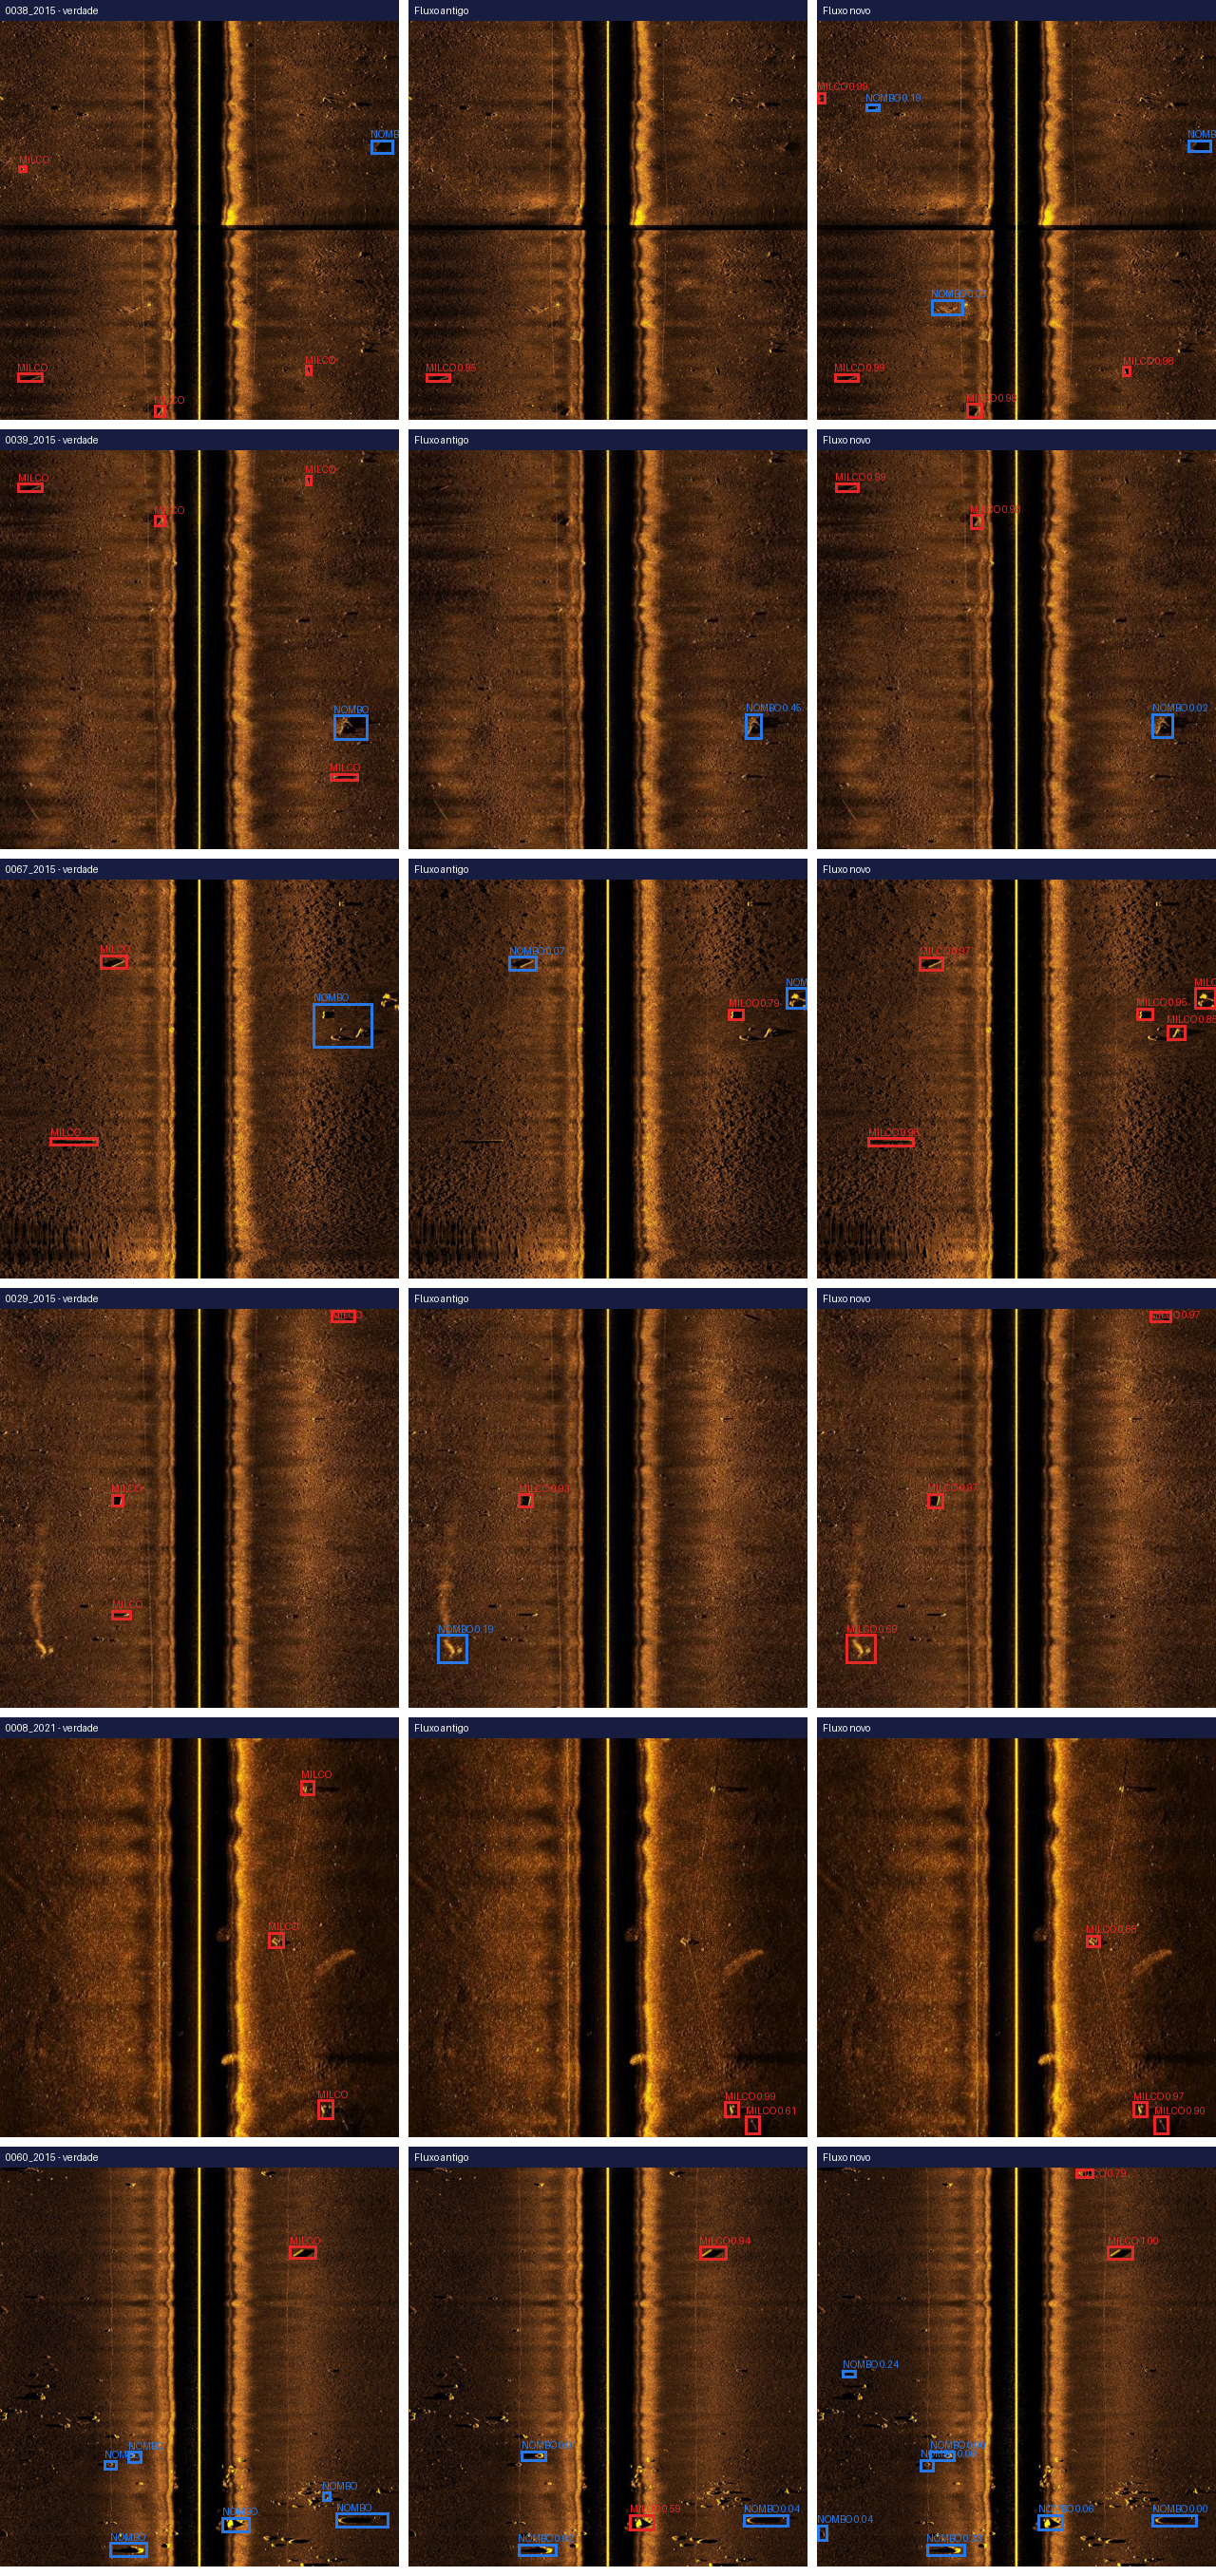

In [5]:
from IPython.display import Image as Img
Img("resultados/figuras/antigo_vs_novo_teste.png", width=1000)

## Usando o fluxo exportado (`pipeline_inferencia.py`, compatível com o Streamlit)

In [6]:
import crop_harness as CH, time
from pipeline_inferencia import Pipeline
pipe = Pipeline()                                   # lê modelos/pipeline_config.json
img = CH.split_imagens()["test"][0]
t = time.time(); det = pipe.analisar(img); print(f"{time.time()-t:.2f} s em CPU")
pd.DataFrame(det)

0.60 s em CPU


""


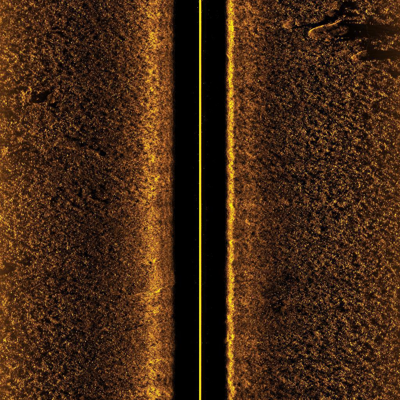

In [7]:
pipe.desenhar(img, det).resize((400, 400))

**Conferência:** nas 40 primeiras imagens de teste, o `pipeline_inferencia.py` com pesos em fp16 reproduz exatamente as decisões do `fase_c.py` (diferença máxima de p(MILCO) = 0,0004). O tempo é de ~0,4 s por imagem em CPU.